In [16]:
import pandas as pd
from pathlib import Path
import json
import re
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

#plt.style.use("seaborn-v0_8-whitegrid")
#pd.set_option("display.max_columns", 50)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXPERIMENT = PROJECT_ROOT / "outputs" / "experiment_1_300k"

FOLD = 10      # valid values for this experiment: 0, ..., 18
RL_SEED = 0    # preliminary_50k contains seed 0
FOLD_DIR = EXPERIMENT / f"fold_{FOLD:03d}"
assert FOLD_DIR.is_dir(), f"Fold directory not found: {FOLD_DIR}"


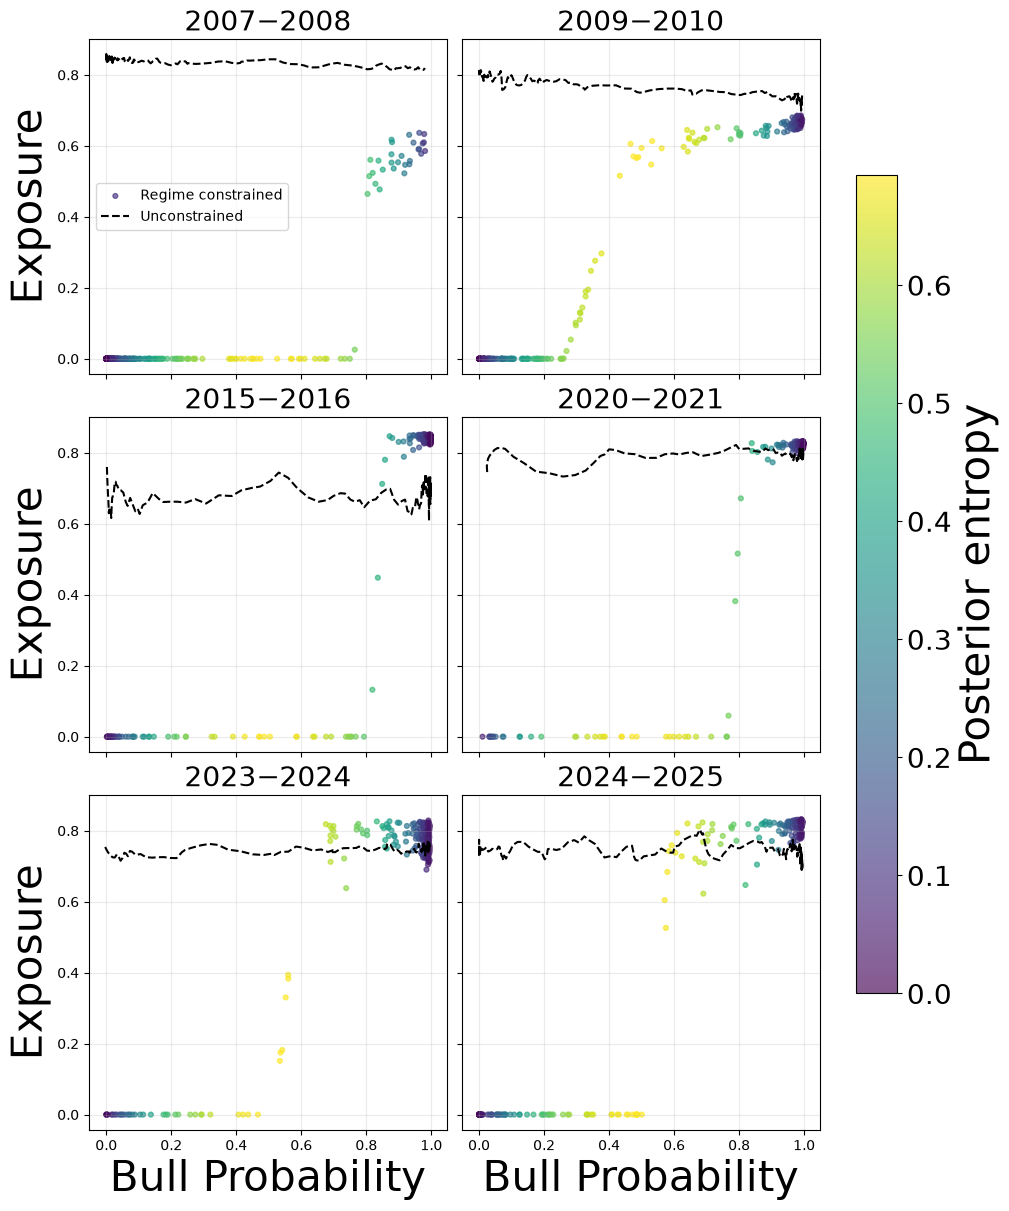

In [ ]:
fold_directories = sorted(path for path in EXPERIMENT.glob("fold_*") if path.is_dir())

selected_fold_names = ["fold_001", "fold_003", "fold_009","fold_014", "fold_017", "fold_018"]
fold_directories = [EXPERIMENT / name for name in selected_fold_names]
fold_directories = [p for p in fold_directories if p.is_dir()]
nrows = 3
ncols = max(1, int(np.ceil(len(fold_directories) / nrows)))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(10,12), sharex=True, sharey=True, constrained_layout=True
)
axes = np.asarray(axes).ravel()
entropy_max = np.log(2.0)  # maximum entropy for a two-state posterior
scatter = None
first =True
for axis, fold_directory in zip(axes, fold_directories):
    fold_split = json.loads((fold_directory / "split_definition.json").read_text())
    start_year = fold_split["test"]["start"][:4]
    end_year = fold_split["test"]["end_exclusive"][:4]
    fold_full = pd.read_parquet(
        fold_directory / "backtests" / f"full_seed_{RL_SEED}.parquet"
    )
    fold_unconstrained= pd.read_parquet(
        fold_directory / "backtests" / f"unconstrained_seed_{RL_SEED}.parquet"
    )

    scatter = axis.scatter(
        fold_full.bull_probability,
        fold_full.exposure,
        c=fold_full["posterior_entropy"],
        cmap="viridis",
        vmin=0.0,
        vmax=entropy_max,
        alpha=0.65,
        s=12,
        label='Regime constrained'
    )

    sorted_vals = fold_unconstrained[['bull_probability','exposure']].sort_values(by='bull_probability')

    bp = savgol_filter(sorted_vals['bull_probability'], window_length=11, polyorder=2)
    exposure = savgol_filter(sorted_vals['exposure'], window_length=11, polyorder=2)

    axis.plot(bp,exposure,ls='--',c='black',label='Unconstrained')
  
    if first:
        axis.legend()
        first = False
    axis.set_title(f"{start_year}-{end_year}",fontsize=20)
    
    axis.grid(alpha=0.25)

for axis in axes[len(fold_directories):]:
    axis.set_visible(False)

for axis in axes[-ncols:]:
    if axis.get_visible():
        axis.set_xlabel("Bull Probability", fontsize=30)

for axis in axes[::ncols]:
    axis.set_ylabel("Exposure", fontsize=30)

if scatter is not None:
    cbar = fig.colorbar(scatter, ax=axes.tolist(), shrink=0.75)
    cbar.ax.tick_params(labelsize=20)
    cbar.set_label("Posterior entropy", fontsize=30)

plt.show()

In [12]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

CSV_PATH = Path("../outputs/cvar_risk_ablation/cvar_risk_ablation_summary.csv")

df = pd.read_csv(CSV_PATH)

full = (
    df.loc[df["strategy"].eq("full")]
      .sort_values(["cvar_confidence", "risk_fraction"])
      .copy()
)

full[[
    "risk_fraction",
    "cvar_confidence",
    "maximum_drawdown_median",
    "cumulative_net_return_median",
]]

import matplotlib.pyplot as plt


def plot_3d_surface_with_heatmap(
    data,
    z_column,
    title,
    z_label,
    scale=1.0,
    output_path=None,
    elev=24,
    azim=-58,
    cmap="viridis",
):
    """
    Plot:
    1. A triangulated 3D surface colored by the z-value.
    2. A heatmap projected onto the x-y plane.
    3. The original observed data points.
    """
    x = data["risk_fraction"].astype(float).to_numpy()
    y = data["cvar_confidence"].astype(float).to_numpy()
    z = data[z_column].astype(float).to_numpy() * scale

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Place the heatmap slightly below the lowest surface value.
    z_range = z.max() - z.min()
    padding = 0.15 * z_range if z_range > 0 else 1.0
    heatmap_floor = z.min() - padding

    # 3D surface colored according to z-values.
    surface = ax.plot_trisurf(
        x,
        y,
        z,
        cmap=cmap,
        linewidth=0.4,
        edgecolor="white",
        antialiased=True,
        alpha=0.9,
    )

    # Heatmap projected onto the x-y floor.
    ax.tricontourf(
        x,
        y,
        z,
        zdir="z",
        offset=heatmap_floor,
        levels=20,
        cmap=cmap,
        alpha=0.85,
    )

    # Show the actual tested configurations.
    ax.scatter(
        x,
        y,
        z,
        s=45,
        c=z,
        cmap=cmap,
        edgecolor="black",
        linewidth=0.6,
    )

    #ax.set_title(title)
    ax.set_xlabel("Risk fraction")
    ax.set_ylabel("CVaR Level")
    ax.set_zlabel(z_label)

    ax.set_xticks(sorted(data["risk_fraction"].unique()))
    ax.set_yticks(sorted(data["cvar_confidence"].unique()))

    # Extend the z-axis downward so the heatmap remains visible.
    ax.set_zlim(heatmap_floor, z.max() + padding * 0.3)
    ax.view_init(elev=elev, azim=azim)

    colorbar = fig.colorbar(
        surface,
        ax=ax,
        shrink=0.65,
        pad=0.10,
    )
    colorbar.set_label(z_label)

    fig.tight_layout()

    if output_path is not None:
        fig.savefig(output_path, bbox_inches="tight")

    plt.show()

    return fig, ax

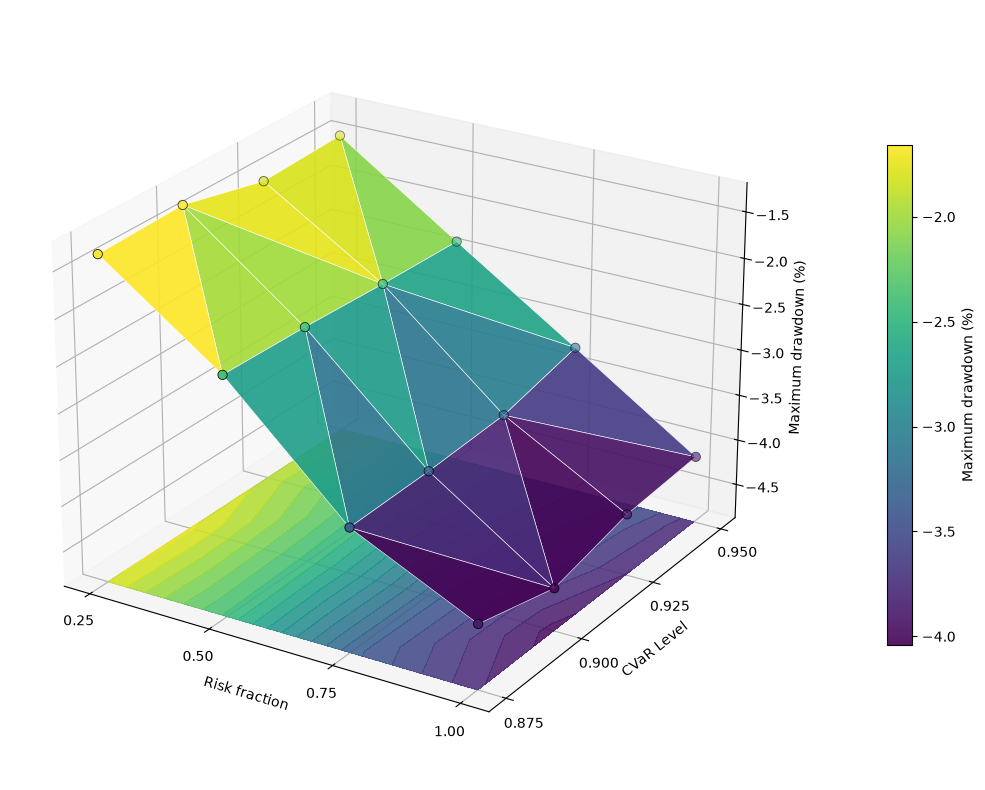

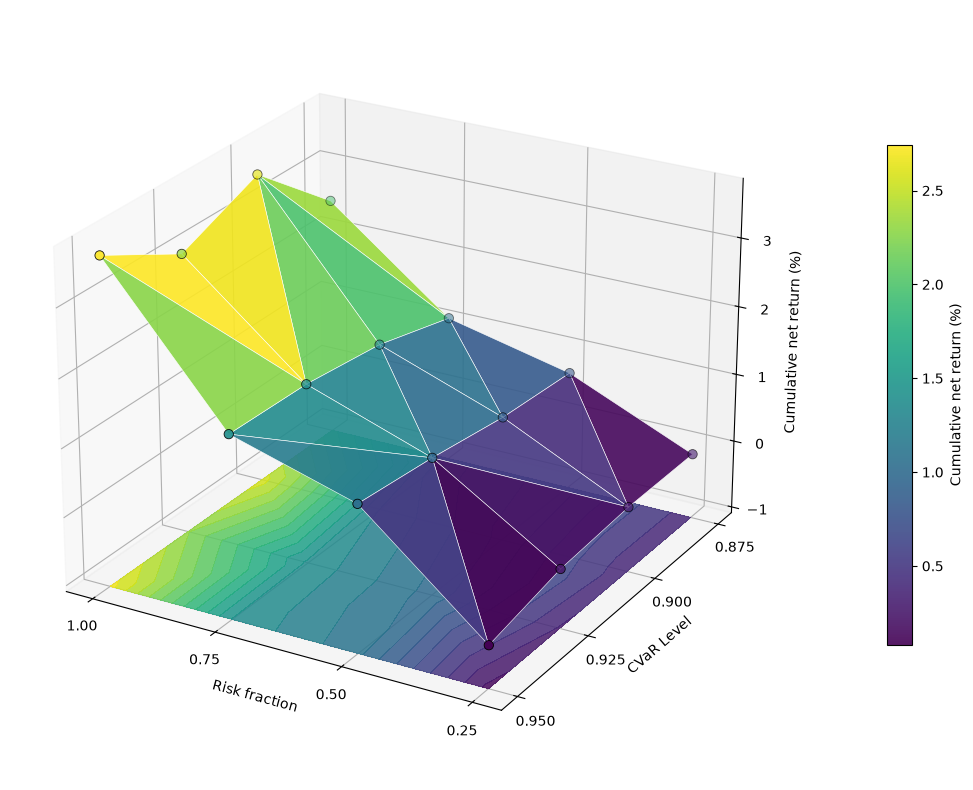

In [ ]:
drawdown_fig, drawdown_ax = plot_3d_surface_with_heatmap(
    data=full,
    z_column="maximum_drawdown_median",
    title="Full strategy: 3D view of median maximum drawdown",
    z_label="Maximum drawdown (%)",
    scale=100,
    output_path="None.pdf",
)


return_fig, return_ax = plot_3d_surface_with_heatmap(
    data=full,
    z_column="cumulative_net_return_median",
    title="Full strategy: 3D view of median cumulative net return",
    z_label="Cumulative net return (%)",
    scale=100,
    output_path="None.pdf",
    azim=120
)

,display_name,cumulative_net_return_median,sharpe_ratio_median,maximum_drawdown_median,annual_turnover_median,transaction_cost_drag_median,average_exposure_median,realized_risk_over_beta_median
0,10% buy-and-hold,1.37%,0.81,-1.24%,0.10,0.01%,10.00%,0.10
1,20% buy-and-hold,2.72%,0.81,-2.47%,0.20,0.02%,20.00%,0.20
2,30% buy-and-hold,4.06%,0.81,-3.69%,0.30,0.03%,30.00%,0.30
3,40% buy-and-hold,5.39%,0.81,-4.90%,0.40,0.04%,40.00%,0.40
4,50% buy-and-hold,6.69%,0.81,-6.09%,0.50,0.05%,50.00%,0.50
5,52% buy-and-hold (matched),6.95%,0.81,-6.33%,0.52,0.05%,52.00%,0.52
6,60% buy-and-hold,7.98%,0.81,-7.28%,0.60,0.06%,60.00%,0.60
7,70% buy-and-hold,9.25%,0.81,-8.45%,0.70,0.07%,70.00%,0.70
8,80% buy-and-hold,10.50%,0.81,-9.62%,0.80,0.08%,80.00%,0.81
9,90% buy-and-hold,11.72%,0.81,-10.77%,0.90,0.09%,90.00%,0.91


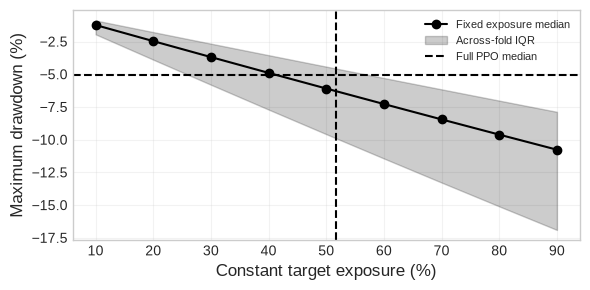

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXPERIMENT = PROJECT_ROOT / "outputs" / "experiment_1_300k"
GRID_EXPOSURES = tuple(range(10, 100, 10))
FIXED_STRATEGIES = tuple(f"buy_hold_{value}" for value in GRID_EXPOSURES)
MATCHED_STRATEGY = "buy_hold_52"
assert EXPERIMENT.is_dir(), f"Experiment not found: {EXPERIMENT}"

metrics = pd.read_parquet(EXPERIMENT / "seed_metrics.parquet")
selected = metrics[metrics["strategy"].isin((*FIXED_STRATEGIES, MATCHED_STRATEGY, "full"))].copy()
fold_metrics = (
    selected.groupby(["strategy", "fold"], as_index=False, observed=True)[
        ["cumulative_net_return", "sharpe_ratio", "maximum_drawdown",
         "annual_turnover", "transaction_cost_drag", "average_exposure",
         "realized_risk_over_beta"]
    ].mean()
)

records = []
for strategy, group in fold_metrics.groupby("strategy", observed=True):
    record = {"strategy": strategy, "folds": group["fold"].nunique()}
    for metric in ["cumulative_net_return", "sharpe_ratio", "maximum_drawdown",
                   "annual_turnover", "transaction_cost_drag", "average_exposure",
                   "realized_risk_over_beta"]:
        values = group[metric].dropna()
        record.update({
            f"{metric}_median": values.median(),
            f"{metric}_q25": values.quantile(0.25),
            f"{metric}_q75": values.quantile(0.75),
            f"{metric}_min": values.min(),
            f"{metric}_max": values.max(),
        })
    records.append(record)
summary = pd.DataFrame(records)
summary["target_exposure"] = summary["strategy"].map(
    {**{f"buy_hold_{value}": value / 100 for value in GRID_EXPOSURES},
     MATCHED_STRATEGY: 0.52}
)
summary["display_name"] = summary["strategy"].map(
    {**{f"buy_hold_{value}": f"{value}% buy-and-hold" for value in GRID_EXPOSURES},
     MATCHED_STRATEGY: "52% buy-and-hold (matched)", "full": "Full PPO"}
)
summary = summary.sort_values(["target_exposure", "strategy"], na_position="last")

display_columns = ["display_name", "cumulative_net_return_median", "sharpe_ratio_median",
                   "maximum_drawdown_median", "annual_turnover_median",
                   "transaction_cost_drag_median", "average_exposure_median",
                   "realized_risk_over_beta_median"]
display(summary[display_columns].style.format({
    "cumulative_net_return_median": "{:.2%}", "sharpe_ratio_median": "{:.2f}",
    "maximum_drawdown_median": "{:.2%}", "annual_turnover_median": "{:.2f}",
    "transaction_cost_drag_median": "{:.2%}", "average_exposure_median": "{:.2%}",
    "realized_risk_over_beta_median": "{:.2f}",
}))





grid = summary[
    summary["strategy"].isin(FIXED_STRATEGIES) &
    summary["target_exposure"].between(0.10, 0.90)
].sort_values("target_exposure")

full = summary.loc[summary["strategy"] == "full"].iloc[0]


fig, axis = plt.subplots(1, 1, figsize=(6, 3))
x = 100 * grid["target_exposure"].to_numpy()
metric = "maximum_drawdown"
label= "Maximum drawdown (%)"
   
median = 100 * grid[f"{metric}_median"].to_numpy()
q25 = 100* grid[f"{metric}_q25"].to_numpy()
q75 = 100 * grid[f"{metric}_q75"].to_numpy()
axis.plot(x, median, marker="o", label="Fixed exposure median",color='black')
axis.fill_between(x, q25, q75, alpha=0.2, label="Across-fold IQR",color='black')
axis.axhline(100 * full[f"{metric}_median"], color="black", linestyle="--",
                label="Full PPO median")
axis.axvline(100 * full["average_exposure_median"], color="black", linestyle="--"),

# axis.axvline(100 * full["average_exposure_median"], color="black", linestyle=":",
#                 label="Full PPO median exposure")
axis.set_xlabel("Constant target exposure (%)",fontsize=12)
axis.set_ylabel(label, fontsize=12)
axis.grid(alpha=0.25)
axis.legend(fontsize=8)
fig.tight_layout()
plt.show()


## SAC revision: cap and PPO utilization decomposition

The following cells reproduce `cap_policy_decomposition.png` and `utilization_associations.png` from the saved out-of-sample Full-PPO trajectories. Utilization plots exclude observations with essentially zero caps.

In [2]:
from caprl.data.features import build_market_features
from caprl.data.loader import load_price_csv
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXPERIMENT = PROJECT_ROOT / "outputs" / "experiment_1_300k"
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "spy.csv"
FIGURE_DIR = PROJECT_ROOT / "paper" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

prices = load_price_csv(DATA_PATH)["adjusted_close"]
market_features = build_market_features(prices)

full_ppo_rows = []
trajectory_paths = sorted(EXPERIMENT.glob("fold_*/backtests/full_seed_*.parquet"))
assert trajectory_paths, f"No Full-PPO trajectories found below {EXPERIMENT}"
for trajectory_path in trajectory_paths:
    trajectory = pd.read_parquet(trajectory_path)
    trajectory = trajectory.join(
        market_features[["realized_vol_20d"]], how="left"
    )
    trajectory["fold"] = int(trajectory_path.parents[1].name.split("_")[-1])
    trajectory["seed"] = int(trajectory_path.stem.split("_")[-1])
    full_ppo_rows.append(trajectory)

full_ppo = pd.concat(full_ppo_rows).sort_index()
positive_cap = full_ppo[full_ppo["cap"] > 1e-10].copy()
assert positive_cap["raw_action"].between(0, 1).all()
print(
    f"Loaded {len(full_ppo):,} out-of-sample rows from "
    f"{full_ppo['fold'].nunique()} folds and {full_ppo['seed'].nunique()} seeds; "
    f"{len(positive_cap):,} rows have positive caps."
)

Loaded 23,795 out-of-sample rows from 19 folds and 5 seeds; 15,670 rows have positive caps.


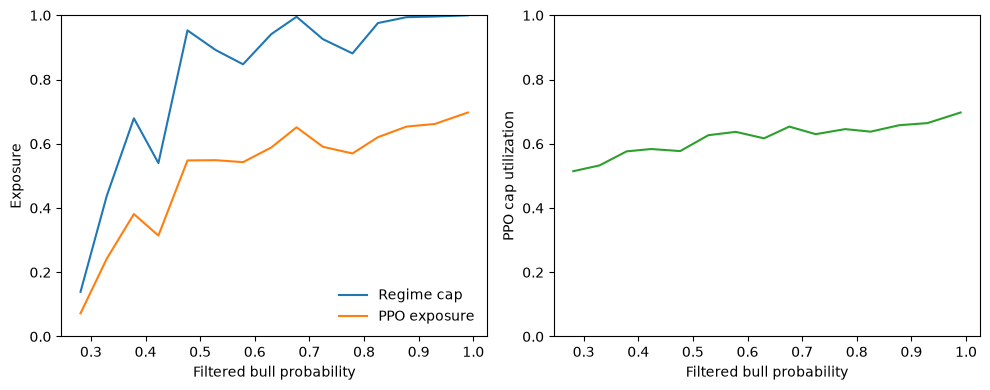

In [9]:
belief_bins = pd.cut(
    positive_cap["bull_probability"],
    np.linspace(0.0, 1.0, 21),
    include_lowest=True,
)
by_belief = positive_cap.groupby(belief_bins, observed=True).agg(
    bull_probability=("bull_probability", "mean"),
    cap=("cap", "mean"),
    exposure=("exposure", "mean"),
    utilization=("raw_action", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(
    by_belief["bull_probability"], by_belief["cap"], label="Regime cap"
)
axes[0].plot(
    by_belief["bull_probability"],
    by_belief["exposure"],
    label="PPO exposure",
)
axes[0].set(
    xlabel="Filtered bull probability", ylabel="Exposure", ylim=(0, 1)
)
axes[0].legend(frameon=False)
axes[1].plot(
    by_belief["bull_probability"],
    by_belief["utilization"],
    color="tab:green",
)
axes[1].set(
    xlabel="Filtered bull probability",
    ylabel="PPO cap utilization",
    ylim=(0, 1),
)
fig.tight_layout()
#figure_path = FIGURE_DIR / "cap_policy_decomposition.png"
#fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
#print(f"Saved {figure_path}")

In [3]:
from matplotlib.ticker import PercentFormatter, MultipleLocator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --------------------------------------------------
# Prepare binned data
# --------------------------------------------------
positive_cap = full_ppo[full_ppo["cap"] > 1e-10].copy()

bin_edges = np.linspace(0, 1, 21)
positive_cap["belief_bin"] = pd.cut(
    positive_cap["bull_probability"],
    bins=bin_edges,
    include_lowest=True,
)

# Point estimates
by_belief = (
    positive_cap
    .groupby("belief_bin", observed=True)
    .agg(
        bull_probability=("bull_probability", "mean"),
        cap=("cap", "mean"),
        exposure=("exposure", "mean"),
        utilization=("raw_action", "mean"),
        n=("cap", "size"),
    )
    .reset_index()
    .sort_values("bull_probability")
)

# --------------------------------------------------
# Cluster bootstrap for uncertainty bands
# --------------------------------------------------
def bootstrap_binned_means(
    df,
    cluster_cols=("fold", "seed"),
    n_boot=1000,
    alpha=0.05,
    random_state=7,
):
    rng = np.random.default_rng(random_state)

    grouped = {
        key: g.copy()
        for key, g in df.groupby(list(cluster_cols), sort=False)
    }
    cluster_keys = list(grouped.keys())
    n_clusters = len(cluster_keys)

    boot_frames = []

    for b in range(n_boot):
        sampled_idx = rng.integers(0, n_clusters, size=n_clusters)
        sampled_keys = [cluster_keys[i] for i in sampled_idx]

        sample = pd.concat(
            [grouped[key] for key in sampled_keys],
            axis=0,
            ignore_index=True,
        )

        boot_stat = (
            sample
            .groupby("belief_bin", observed=True)
            .agg(
                cap=("cap", "mean"),
                exposure=("exposure", "mean"),
                utilization=("raw_action", "mean"),
            )
            .reset_index()
        )
        boot_stat["bootstrap"] = b
        boot_frames.append(boot_stat)

    boot_df = pd.concat(boot_frames, ignore_index=True)

    lower_q = alpha / 2
    upper_q = 1 - alpha / 2

    ci = (
        boot_df
        .groupby("belief_bin", observed=True)
        .agg(
            cap_lo=("cap", lambda x: x.quantile(lower_q)),
            cap_hi=("cap", lambda x: x.quantile(upper_q)),
            exposure_lo=("exposure", lambda x: x.quantile(lower_q)),
            exposure_hi=("exposure", lambda x: x.quantile(upper_q)),
            utilization_lo=("utilization", lambda x: x.quantile(lower_q)),
            utilization_hi=("utilization", lambda x: x.quantile(upper_q)),
        )
        .reset_index()
    )

    return ci

ci = bootstrap_binned_means(
    positive_cap,
    cluster_cols=("fold","seed"),# "seed"),
    n_boot=500,      # reduce to 300 if too slow
    alpha=0.05,
    random_state=7,
)

# Merge point estimates with confidence intervals
by_belief = (
    by_belief
    .merge(ci, on="belief_bin", how="left")
    .sort_values("bull_probability")
    .reset_index(drop=True)
)



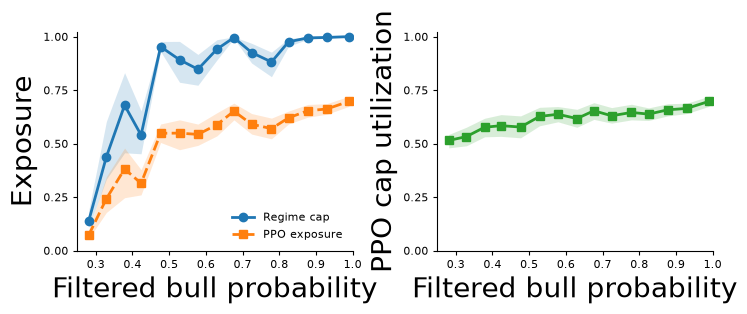

In [11]:
# Colorblind-friendly palette
COLORS = {
    "cap": "tab:blue",
    "exposure": "tab:orange",
    "utilization": "tab:green",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 400,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.2, 2.8),
    layout="constrained",
)

x = by_belief["bull_probability"]

# --------------------------------------------------
# Panel (a): cap and exposure with uncertainty bands
# --------------------------------------------------
axes[0].plot(
    x, by_belief["cap"],
    color=COLORS["cap"],
    linewidth=2.0,
    label="Regime cap",
    marker='o'
)
axes[0].fill_between(
    x,
    by_belief["cap_lo"],
    by_belief["cap_hi"],
    color=COLORS["cap"],
    alpha=0.18,
    linewidth=0,
)

axes[0].plot(
    x, by_belief["exposure"],
    color=COLORS["exposure"],
    linewidth=2.0,
    linestyle="--",
    label="PPO exposure",
    marker='s'
)
axes[0].fill_between(
    x,
    by_belief["exposure_lo"],
    by_belief["exposure_hi"],
    color=COLORS["exposure"],
    alpha=0.18,
    linewidth=0,
)

#axes[0].set_title("(a) Regime cap and exposure", loc="left", fontweight="bold")
axes[0].set_ylabel("Exposure",size=20)
axes[0].legend(frameon=False, loc="lower right")

# --------------------------------------------------
# Panel (b): utilization with uncertainty band
# --------------------------------------------------
axes[1].plot(
    x, by_belief["utilization"],
    color=COLORS["utilization"],
    linewidth=2.0,
    marker='s'
)
axes[1].fill_between(
    x,
    by_belief["utilization_lo"],
    by_belief["utilization_hi"],
    color=COLORS["utilization"],
    alpha=0.18,
    linewidth=0,
)

#axes[1].set_title("(b) PPO cap utilization", loc="left", fontweight="bold")
axes[1].set_ylabel("PPO cap utilization",size=20)

# --------------------------------------------------
# Shared formatting
# --------------------------------------------------
xmin = max(0.0, np.floor(x.min() / 0.05) * 0.05)

for ax in axes:
    ax.set_xlim(xmin, 1.0)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Filtered bull probability",size=20)

    ax.xaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_major_locator(MultipleLocator(0.25))
    #ax.yaxis.set_major_formatter(PercentFormatter(1.0))

    #ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

fig.savefig(FIGURE_DIR / "cap_policy_decomposition.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "cap_policy_decomposition.png", dpi=400, bbox_inches="tight")
plt.show()


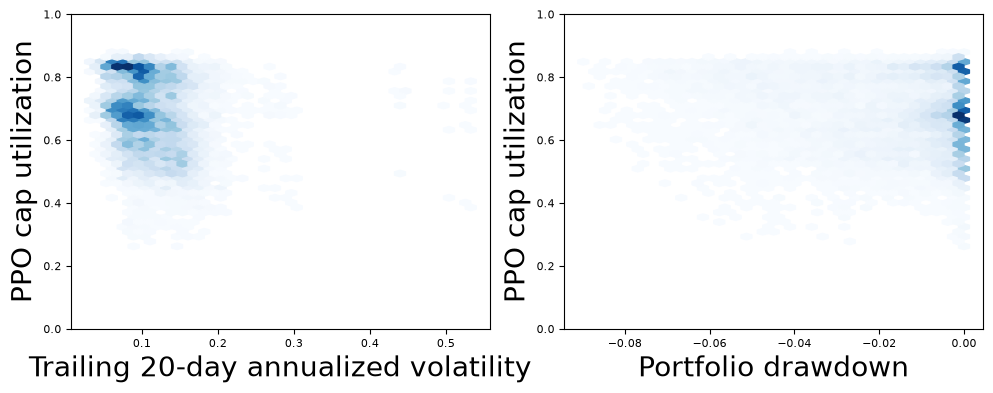

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hexbin(
    positive_cap["realized_vol_20d"],
    positive_cap["raw_action"],
    gridsize=35,
    mincnt=1,
    cmap="Blues",
)
# axes[0].set(
#     xlabel="Trailing 20-day annualized volatility",
#     ylabel="PPO cap utilization", xlabel_kw={"fontsize": 20},
#     ylabel_kw={"fontsize": 20}
# )
axes[0].set_xlabel("Trailing 20-day annualized volatility", fontsize=20)
axes[0].set_ylabel("PPO cap utilization", fontsize=20)

axes[1].hexbin(
    positive_cap["drawdown"],
    positive_cap["raw_action"],
    gridsize=35,
    mincnt=1,
    cmap="Blues",
)
# axes[1].set(
#     xlabel="Portfolio drawdown", ylabel="PPO cap utilization"
# )
axes[1].set_xlabel("Portfolio drawdown", fontsize=20)
axes[1].set_ylabel("PPO cap utilization", fontsize=20)
for axis in axes:
    axis.set_ylim(0, 1)
fig.tight_layout()
figure_path = FIGURE_DIR / "utilization_associations.pdf"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()